# MLP_JK_06 — Patient offset: predict each slide's level separately

**Why this notebook:** a large part of the test error comes from a new patient's (or slide's) **overall gene level** being off: the model gets the pattern inside the tissue partly right, but the whole slide is shifted up or down. Here we test whether predicting each slide's level separately, from its images, fixes that.

**Setups** (all MLPs use setup D's input: center PCA 256 + 3×3 average PCA 256; same MLP settings as MLP_JK_03–05)

| Setup | What the MLP learns | Test prediction |
|---|---|---|
| **D** | absolute expression, as in MLP_JK_03 | `gene_mean + k × (MLP − gene_mean)` |
| **L0** pattern only | each spot's expression **minus its own slide's mean** (the "pattern") | `training gene mean + k × pattern` |
| **L** level + pattern | the same pattern MLP as L0, **plus a level model** that predicts each slide's mean from the slide's average embedding | `predicted slide level + k × pattern` |
| **O** ORACLE | not a model: D's predictions with each test slide's mean replaced by the **true** test slide mean | uses **test labels**; a ceiling only, never used for choosing |

**The level model:** one row per section. The input is the slide average (the mean raw embedding of all its spots, images only) after StandardScaler + PCA 32 fit on training sections. The output is that section's mean expression of the 50 genes. It's a ridge regression with alpha chosen on the 4 inner validation groups, trained on training sections only.

**The error split:** each setup's test MSE is split into a **level error** (predicted vs. true slide means) and a **pattern error** (what's left inside each slide). The two add up to the test MSE.

**How to read it (decided before running)**
- L0 vs. D: does centering alone help, or does dropping all slide-level information hurt?
- L vs. D and L vs. L0: does the level model fix the level error?
- O vs. D: how much could be gained with perfect slide levels (the ceiling)?

**No leakage:** test expression is used only for scoring and for the clearly labeled oracle O. Slide averages use images only. PCA, gene means, slide centering and ridge are all fit on training data.

**Checks:** ridge raw must reproduce Notebook 5 (0.187), and D must reproduce MLP_JK_03's D (MSE 0.958, PCC 0.206), or the notebook stops.

**Best model:** `best_check.csv` reports whether any setup passes the usual rule against the current MLP_JK_Best, but this notebook does **not** change MLP_JK_Best.

**Reads** `~/JHU/BDD/datasets/BDD_HEST`, Notebook 5's scores, and `~/JHU/BDD/MLP_JK/results/` (MLP_JK_03, MLP_JK_Best).
**Saves** to `~/JHU/BDD/MLP_JK/results/MLP_JK_06/` and adds rows to `~/JHU/BDD/MLP_JK/results/all_results.csv`.

In [1]:
import os
import copy
import json
import time
import datetime
import numpy as np
import pandas as pd
import scipy.sparse
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import Ridge
from sklearn.neighbors import NearestNeighbors

## Settings

**Paths**
- `NOTEBOOK_5_DIR`: Notebook 5's saved scores (ridge check).
- `CHECK_DIR`: MLP_JK_03's saved scores. Setup D must reproduce its setup D.
- `BEST_DIR`: the current MLP_JK_Best's saved scores, for the best check (report only).
- `LOG_RESULTS`: whether this notebook adds its rows to `all_results.csv`.

**Evaluation** (copied from Notebook 5): `N_FOLDS`, `N_GENES`, `MIN_TEST_SD`, `SEED`, and `N_INNER_FOLDS`, `ALPHAS` (the ridge settings, also used for the level model's alpha grid).

**Inputs:** `NEIGHBOR_DISTANCE = 1.8` (3×3), `N_PCS = 256` (center and 3×3 average), `SLIDE_PCS = 32` (slide average, fit on ~50 training sections).

**MLP** (fixed, the same as MLP_JK_03–05): `HIDDEN_SIZE`, `DROPOUT`, `WEIGHT_DECAY`, `LEARNING_RATE`, `BATCH_SIZE`, `MAX_EPOCHS`, `PATIENCE`, `SHRINK_FACTORS` (`k` values), `N_VAL_GROUPS`, `N_FINAL_SEEDS`.

**D check:** how far D may be from MLP_JK_03's D before the notebook stops.

In [2]:
DATA_DIR = os.path.expanduser("~/JHU/BDD/datasets/BDD_HEST")
NOTEBOOK_5_DIR = os.path.expanduser("~/JHU/BDD/Experiments/smoothing_control")
MLP_DIR = os.path.expanduser("~/JHU/BDD/MLP_JK")
CHECK_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_03")
BEST_DIR = os.path.join(MLP_DIR, "results", "MLP_JK_Best")
NOTEBOOK_NAME = "MLP_JK_06"
LOG_RESULTS = True
OUT_DIR = os.path.join(MLP_DIR, "results", NOTEBOOK_NAME)
RESULTS_LOG = os.path.join(MLP_DIR, "results", "all_results.csv")

N_FOLDS = 4
N_INNER_FOLDS = 3
N_GENES = 50
ALPHAS = np.logspace(-2, 7, 40)
MIN_TEST_SD = 0.05
SEED = 0

NEIGHBOR_DISTANCE = 1.8
N_PCS = 256
SLIDE_PCS = 32

HIDDEN_SIZE = 128
DROPOUT = 0.3
WEIGHT_DECAY = 1e-3
LEARNING_RATE = 3e-4
BATCH_SIZE = 256
MAX_EPOCHS = 100
PATIENCE = 10
SHRINK_FACTORS = [0.2, 0.4, 0.6, 0.8, 1.0]
N_VAL_GROUPS = 4
N_FINAL_SEEDS = 3

CHECK_PCC_TOLERANCE = 0.01
CHECK_MSE_TOLERANCE = 0.005

Names of the setups, the device (Apple GPU `mps` if available, otherwise CPU), and fixed seeds. The Apple GPU isn't perfectly deterministic, so a rerun can differ in the third decimal.

In [3]:
SETUP_NAMES = {
    "D": "D center + 3x3",
    "L0": "L0 pattern only",
    "L": "L level + pattern",
    "O": "O ORACLE (uses test labels)",
}
REAL_SETUPS = ["D", "L0", "L"]

if torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("Device:", device)

np.random.seed(SEED)
torch.manual_seed(SEED)

EXPRESSION_DIR = os.path.join(DATA_DIR, "expression")
EMBEDDING_DIR = os.path.join(DATA_DIR, "embeddings")
os.makedirs(OUT_DIR, exist_ok=True)


def save_figure(name):
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")

Device: mps


## Step 1. Load embeddings and expression (copied from Notebook 5)

Each section's embedding file must list the same barcodes, in the same order, as the spot table, and each expression matrix must have one row per spot and one column per gene. The `assert` lines stop the notebook if not.

In [4]:
spot_table = pd.read_csv(os.path.join(DATA_DIR, "spot_table.csv"))
with open(os.path.join(DATA_DIR, "genes.txt")) as f:
    all_genes = np.array(f.read().split())

X_parts = []
Y_parts = []
spot_parts = []

for sample_id in spot_table["sample_id"].unique():
    section_spots = spot_table[spot_table["sample_id"] == sample_id].sort_values("row_in_sample")

    saved = np.load(os.path.join(EMBEDDING_DIR, f"{sample_id}.npz"), allow_pickle=True)
    assert np.array_equal(saved["barcode"], section_spots["barcode"].to_numpy()), \
        f"{sample_id}: embedding rows don't match the spot table"

    expression = scipy.sparse.load_npz(os.path.join(EXPRESSION_DIR, f"{sample_id}.npz"))
    assert expression.shape == (len(section_spots), len(all_genes)), \
        f"{sample_id}: expression shape doesn't match the spot table and genes.txt"

    X_parts.append(saved["embeddings"].astype(np.float32))
    Y_parts.append(expression)
    spot_parts.append(section_spots)

X_raw = np.concatenate(X_parts, axis=0)
Y = scipy.sparse.vstack(Y_parts).tocsc()
spots = pd.concat(spot_parts, ignore_index=True)
del X_parts, Y_parts
patient_array = spots["patient"].to_numpy()
section_array = spots["sample_id"].to_numpy()

print("X (embeddings):", X_raw.shape)
print("Y (log1p expression):", Y.shape)
print("Sections:", spots["sample_id"].nunique(), " Patients:", spots["patient"].nunique())

X (embeddings): (30600, 4608)
Y (log1p expression): (30600, 11787)
Sections: 68  Patients: 23


## Step 2. Real 3×3 neighborhoods (same definition as Notebook 5)

For each section, the spot spacing = median distance from a spot to its closest other spot. A spot's neighborhood = every spot on the same section within 1.8 spacings (the 3×3 square), **including the spot itself**. Edge spots are averaged over what exists.

In [5]:
def find_neighborhoods(max_distance):
    neighborhoods = [None] * len(spots)
    for sample_id in np.unique(section_array):
        rows = np.where(section_array == sample_id)[0]
        xy = spots.loc[rows, ["x", "y"]].to_numpy().astype(np.float64)
        finder = NearestNeighbors().fit(xy)
        distances, _ = finder.kneighbors(xy, n_neighbors=2)
        spacing = np.median(distances[:, 1])
        nearby_lists = finder.radius_neighbors(xy, radius=max_distance * spacing, return_distance=False)
        for i, nearby in enumerate(nearby_lists):
            neighborhoods[rows[i]] = rows[nearby]
    return neighborhoods


def neighbor_mean(X, neighborhoods):
    X_smoothed = np.zeros_like(X)
    for i, nearby in enumerate(neighborhoods):
        X_smoothed[i] = X[nearby].mean(axis=0)
    return X_smoothed


real_neighborhoods = find_neighborhoods(NEIGHBOR_DISTANCE)
sizes = np.array([len(n) for n in real_neighborhoods])
print(f"3x3: spots per neighborhood (incl. itself) mean {sizes.mean():.2f}, min {sizes.min()}, max {sizes.max()}")

3x3: spots per neighborhood (incl. itself) mean 8.30, min 1, max 10


## Step 3. Patient folds (copied from Notebook 5)

`GroupKFold` puts every spot of a patient in the same fold, so the test patients are never seen in training. Each fold is the test set once.

In [6]:
fold_of_spot = np.zeros(len(spots), dtype=int)
splitter = GroupKFold(n_splits=N_FOLDS)
for fold, (train_index, test_index) in enumerate(splitter.split(X_raw, groups=patient_array)):
    fold_of_spot[test_index] = fold

for fold in range(N_FOLDS):
    print(f"fold {fold}: {np.sum(fold_of_spot == fold)} test spots | {sorted(np.unique(patient_array[fold_of_spot == fold]))}")

fold 0: 7625 test spots | ['BC23209', 'BC23803', 'BC23810', 'BC23895', 'BC23901', 'BC23903']
fold 1: 7950 test spots | ['BC23268', 'BC23287', 'BC23377', 'BC23450', 'BC23506', 'BC24220']
fold 2: 7876 test spots | ['BC23269', 'BC23270', 'BC23277', 'BC23508', 'BC23567', 'BC24105']
fold 3: 7149 test spots | ['BC23272', 'BC23288', 'BC23944', 'BC24044', 'BC24223']


## Step 4. Gene choice and scoring (copied from Notebook 5)

**`choose_genes`**: the 50 genes with the highest variance across the **training** spots of a fold.

**`score_model`** gives two kinds of score for every gene:
- **Pooled**: over all test spots of the fold together. **PCC** = correlation between predicted and true expression. **NRMSE** = prediction error divided by the gene's spread (SD) in the test spots.
- **Within patient**: the same, but inside one test patient at a time, then averaged. This asks whether the model ranks spots correctly *within* a tissue, not just whether it gets the patient's overall level right.

The **mean predictor** predicts the training mean for every spot. Its PCC is undefined (the prediction is constant), and its NRMSE is the bar any useful model should get under.

In [7]:
def choose_genes(train_index):
    Y_train = Y[train_index]
    mean = np.asarray(Y_train.mean(axis=0)).ravel()
    mean_of_squares = np.asarray(Y_train.multiply(Y_train).mean(axis=0)).ravel()
    variance = mean_of_squares - mean ** 2
    return np.argsort(variance)[::-1][:N_GENES]


def pcc(a, b):
    if np.std(a) < 1e-6 or np.std(b) < 1e-6:
        return np.nan
    return np.corrcoef(a, b)[0, 1]


def score_model(model_name, fold_results, prediction_key):
    pooled_rows = []
    within_rows = []
    for r in fold_results:
        y_true = r["y_test"]
        y_pred = r[prediction_key]
        test_patients = patient_array[r["test_index"]]

        for g, gene in enumerate(r["genes"]):
            sd = np.std(y_true[:, g])
            rmse = np.sqrt(np.mean((y_true[:, g] - y_pred[:, g]) ** 2))
            pooled_rows.append({
                "model": model_name, "fold": r["fold"], "gene": gene,
                "PCC": pcc(y_true[:, g], y_pred[:, g]),
                "NRMSE": rmse / sd if sd >= MIN_TEST_SD else np.nan,
                "alpha": r["alpha"][g] if prediction_key == "y_pred" else np.nan,
            })

        for patient in np.unique(test_patients):
            rows = test_patients == patient
            for g, gene in enumerate(r["genes"]):
                t = y_true[rows, g]
                p = y_pred[rows, g]
                sd = np.std(t)
                if sd < MIN_TEST_SD:
                    continue
                centered_mse = np.mean(((t - t.mean()) - (p - p.mean())) ** 2)
                within_rows.append({
                    "model": model_name, "fold": r["fold"], "patient": patient, "gene": gene,
                    "PCC_within": pcc(t, p),
                    "NRMSE_within": np.sqrt(np.mean((t - p) ** 2)) / sd,
                    "NRMSE_centered": np.sqrt(centered_mse) / sd,
                })
    return pd.DataFrame(pooled_rows), pd.DataFrame(within_rows)

## Step 5. Ridge on raw embeddings (copied from Notebook 5), and the reproduction check

Inside each fold, using **training spots only**: choose the top-50 genes, fit StandardScaler + PCA 256, choose λ per gene with a 3-group patient split of the training patients, fit ridge, predict the test patients. The mean predictor comes from the same fold (the training mean of each gene).

Then the **check**: the pooled PCC and NRMSE must match Notebook 5's `ridge raw` (0.187 / 1.092). If they don't, the `assert` stops the notebook here, because then the setup isn't the same and nothing below would be comparable.

In [8]:
def choose_alpha_per_gene(P_train, y_train, inner_groups):
    n_inner = min(N_INNER_FOLDS, len(np.unique(inner_groups)))
    inner_splits = GroupKFold(n_splits=n_inner).split(P_train, groups=inner_groups)

    errors = np.zeros((len(ALPHAS), y_train.shape[1]))
    for inner_train, inner_val in inner_splits:
        for a, alpha in enumerate(ALPHAS):
            model = Ridge(alpha=alpha)
            model.fit(P_train[inner_train], y_train[inner_train])
            prediction = model.predict(P_train[inner_val])
            errors[a] += np.mean((prediction - y_train[inner_val]) ** 2, axis=0)

    best = np.argmin(errors, axis=0)
    return ALPHAS[best]


def fit_and_predict(P_train, y_train, P_test, alpha_per_gene):
    y_pred = np.zeros((P_test.shape[0], y_train.shape[1]))
    for alpha in np.unique(alpha_per_gene):
        genes_with_this_alpha = np.where(alpha_per_gene == alpha)[0]
        model = Ridge(alpha=alpha)
        model.fit(P_train, y_train[:, genes_with_this_alpha])
        y_pred[:, genes_with_this_alpha] = model.predict(P_test).reshape(len(P_test), -1)
    return y_pred


def run_ridge_fold(X, fold):
    is_test = fold_of_spot == fold
    train_index = np.where(~is_test)[0]
    test_index = np.where(is_test)[0]

    gene_index = choose_genes(train_index)
    y_train = Y[train_index][:, gene_index].toarray()
    y_test = Y[test_index][:, gene_index].toarray()

    scaler = StandardScaler(copy=False)
    Z_train = scaler.fit_transform(X[train_index])
    Z_test = scaler.transform(X[test_index])

    pca = PCA(n_components=N_PCS, random_state=SEED, copy=False)
    P_train = pca.fit_transform(Z_train)
    P_test = pca.transform(Z_test)

    alpha_per_gene = choose_alpha_per_gene(P_train, y_train, patient_array[train_index])
    y_pred = fit_and_predict(P_train, y_train, P_test, alpha_per_gene)
    y_mean = np.tile(y_train.mean(axis=0), (len(test_index), 1))

    return {
        "fold": fold,
        "test_index": test_index,
        "genes": all_genes[gene_index],
        "y_test": y_test,
        "y_pred": y_pred,
        "y_mean": y_mean,
        "alpha": alpha_per_gene,
    }


start_time = time.time()
ridge_results = []
for fold in range(N_FOLDS):
    ridge_results.append(run_ridge_fold(X_raw, fold))
    print(f"ridge raw fold {fold} done  ({(time.time() - start_time) / 60:.1f} min)", flush=True)

ridge raw fold 0 done  (0.1 min)


ridge raw fold 1 done  (0.2 min)


ridge raw fold 2 done  (0.3 min)


ridge raw fold 3 done  (0.4 min)


In [9]:
mean_pooled, mean_within = score_model("mean predictor", ridge_results, "y_mean")
ridge_pooled, ridge_within = score_model("ridge raw", ridge_results, "y_pred")

notebook_5_summary = pd.read_csv(os.path.join(NOTEBOOK_5_DIR, "summary.csv")).set_index("model")
our_pcc = ridge_pooled["PCC"].mean()
our_nrmse = ridge_pooled["NRMSE"].mean()
notebook_5_pcc = notebook_5_summary.loc["ridge raw", "pooled_PCC"]
notebook_5_nrmse = notebook_5_summary.loc["ridge raw", "pooled_NRMSE"]

print(f"ridge raw, this notebook: pooled PCC {our_pcc:.4f}, NRMSE {our_nrmse:.4f}")
print(f"ridge raw, Notebook 5:    pooled PCC {notebook_5_pcc:.4f}, NRMSE {notebook_5_nrmse:.4f}")

assert abs(our_pcc - notebook_5_pcc) < 0.001 and abs(our_nrmse - notebook_5_nrmse) < 0.001, \
    "Ridge rerun does not reproduce Notebook 5. Stop and find out why before going further."
print("Reproduces Notebook 5.")

ridge raw, this notebook: pooled PCC 0.1868, NRMSE 1.0917
ridge raw, Notebook 5:    pooled PCC 0.1868, NRMSE 1.0917
Reproduces Notebook 5.


## Step 6. Sections and slide averages

- `section_ids`: the 68 sections. `section_number[spot]` says which section each spot belongs to, and `section_patient` says which patient each section belongs to.
- `slide_means`: for each section, the plain mean of the raw 4,608-number embeddings of **all** its spots (images only, as in MLP_JK_05). It is the level model's input.

In [10]:
section_ids = np.unique(section_array)
section_number = np.searchsorted(section_ids, section_array)
section_patient = np.array([patient_array[section_array == s][0] for s in section_ids])
section_size = np.bincount(section_number)

slide_means = np.zeros((len(section_ids), X_raw.shape[1]), dtype=np.float32)
for s in range(len(section_ids)):
    slide_means[s] = X_raw[section_number == s].mean(axis=0)

print(f"{len(section_ids)} sections, {section_size.min()}-{section_size.max()} spots each")
print(f"Sections per patient: {pd.Series(section_patient).value_counts().value_counts().sort_index().to_dict()}")

68 sections, 256-713 spots each
Sections per patient: {2: 1, 3: 22}


## Step 7. PCA inputs for every fold

On the fold's **training patients only**:
- `center`: StandardScaler + PCA 256 of the spots' own embeddings.
- `mean_3x3`: StandardScaler + PCA 256 of the 3×3 averaged embeddings (as setup D in MLP_JK_03).
- `slide`: StandardScaler + PCA 32 of the slide averages, fit on **one row per training section**, then applied to all 68 sections. It stays one row per section, because the level model works on sections.

The MLP input (for D, L0 and L) is `center` + `mean_3x3` = 512 numbers.

In [11]:
def pca_256(X, train_index):
    scaler = StandardScaler()
    pca = PCA(n_components=N_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(X[train_index]))
    return pca.transform(scaler.transform(X)).astype(np.float32)


fold_train_index = [np.where(fold_of_spot != fold)[0] for fold in range(N_FOLDS)]
fold_test_index = [np.where(fold_of_spot == fold)[0] for fold in range(N_FOLDS)]
fold_train_sections = []
for fold in range(N_FOLDS):
    training_patients = np.unique(patient_array[fold_train_index[fold]])
    fold_train_sections.append(np.where(np.isin(section_patient, training_patients))[0])

fold_inputs = [{} for fold in range(N_FOLDS)]
start_time = time.time()

for fold in range(N_FOLDS):
    fold_inputs[fold]["center"] = pca_256(X_raw, fold_train_index[fold])
print(f"Center PCAs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

X_average = neighbor_mean(X_raw, real_neighborhoods)
for fold in range(N_FOLDS):
    fold_inputs[fold]["mean_3x3"] = pca_256(X_average, fold_train_index[fold])
del X_average
print(f"3x3 average PCAs done ({(time.time() - start_time) / 60:.1f} min)", flush=True)

for fold in range(N_FOLDS):
    training_sections = fold_train_sections[fold]
    scaler = StandardScaler()
    pca = PCA(n_components=SLIDE_PCS, random_state=SEED)
    pca.fit(scaler.fit_transform(slide_means[training_sections]))
    fold_inputs[fold]["slide"] = pca.transform(scaler.transform(slide_means))
    print(f"fold {fold}: slide PCA fit on {len(training_sections)} training sections, "
          f"keeps {pca.explained_variance_ratio_.sum():.1%} of their variance")

del X_raw


def build_input(fold):
    return np.concatenate([fold_inputs[fold]["center"], fold_inputs[fold]["mean_3x3"]], axis=1)

Center PCAs done (0.3 min)


3x3 average PCAs done (0.6 min)


fold 0: slide PCA fit on 51 training sections, keeps 98.7% of their variance
fold 1: slide PCA fit on 50 training sections, keeps 98.9% of their variance
fold 2: slide PCA fit on 50 training sections, keeps 98.8% of their variance
fold 3: slide PCA fit on 53 training sections, keeps 98.5% of their variance


## Step 8. The MLP, training, and shrinkage (copied from MLP_JK_03/04/05)

**The network**: input → Linear(input, 128) → ReLU → Dropout 0.3 → Linear(128, 50 genes), with no activation at the end (regression).

**`train_mlp`**: Adam (weight decay 1e-3), MSE loss on genes standardized with the training mean and SD, mini-batches of 256. With validation spots, the weights from the best validation epoch are kept, and training stops after `PATIENCE` epochs without improvement. Without validation spots, it trains for a fixed number of epochs.

**`predict`**: dropout off, predictions converted back to log1p units.

**`shrink`**: `train_mean + k × (prediction − train_mean)`. Shrinking doesn't change PCC; it only changes how spread out the predictions are, so `k` is chosen on NRMSE.

In [12]:
class MLP(nn.Module):
    def __init__(self, n_inputs, n_hidden, n_outputs, dropout):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(n_inputs, n_hidden),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(n_hidden, n_outputs),
        )

    def forward(self, x):
        return self.layers(x)


def to_device(array):
    return torch.tensor(np.asarray(array), dtype=torch.float32, device=device)


def predict(trained, P_device, rows):
    model = trained["model"]
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(rows), 4096):
            batch_rows = torch.tensor(rows[start:start + 4096], device=device)
            outputs.append(model(P_device[batch_rows]).cpu().numpy())
    y_scaled = np.concatenate(outputs, axis=0)
    return y_scaled * trained["gene_sd"] + trained["gene_mean"]


def shrink(y_pred, train_mean, k):
    return train_mean + k * (y_pred - train_mean)


def train_mlp(P_device, y_fold, train_rows, val_rows, n_epochs, seed):
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)

    gene_mean = y_fold[train_rows].mean(axis=0)
    gene_sd = y_fold[train_rows].std(axis=0)
    y_scaled = to_device((y_fold - gene_mean) / gene_sd)

    model = MLP(P_device.shape[1], HIDDEN_SIZE, N_GENES, DROPOUT).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_function = nn.MSELoss()

    trained = {
        "model": model,
        "gene_mean": gene_mean,
        "gene_sd": gene_sd,
        "history": [],
        "best_epoch": n_epochs,
    }

    best_val_loss = np.inf
    best_weights = None
    for epoch in range(1, n_epochs + 1):
        model.train()
        shuffled = rng.permutation(train_rows)
        batch_losses = []
        for start in range(0, len(shuffled), BATCH_SIZE):
            batch_rows = torch.tensor(shuffled[start:start + BATCH_SIZE], device=device)
            loss = loss_function(model(P_device[batch_rows]), y_scaled[batch_rows])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            batch_losses.append(loss.item())
        train_loss = np.mean(batch_losses)

        if val_rows is None:
            trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": np.nan})
            continue

        val_pred = predict(trained, P_device, val_rows)
        val_loss = np.mean(((val_pred - y_fold[val_rows]) / gene_sd) ** 2)
        trained["history"].append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss})

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            trained["best_epoch"] = epoch
            best_weights = copy.deepcopy(model.state_dict())
        elif epoch - trained["best_epoch"] >= PATIENCE:
            break

    if best_weights is not None:
        model.load_state_dict(best_weights)
    return trained

## Step 9. Slide levels, centering, the level model, and the error split

**`section_levels(y, sections)`**: the mean expression of each listed section (one row per section). It's only ever called with **training** sections, except in the scoring and oracle code at the end, which uses test values on purpose.

**Slide-centered targets (the "pattern")**: each training spot's expression minus its own section's mean. The pattern MLP is the same `train_mlp` as D, just given these targets instead of the raw ones. A section always belongs to one patient, so in every split all of a section's spots are on the same side. The centering is therefore exact for every group of training patients: the fit patients and the validation patients are each centered with their own section means (both are training patients).

**The level model**: ridge regression from the slide PCA (32 numbers) to the section's mean expression (50 genes), with one row per section. **`choose_level_alpha`** tries every alpha on the 4 inner validation groups. Each time, it fits on the other groups' sections, predicts the held-out sections' means, and measures the MSE against their true means (every section counts equally). The alpha with the lowest average MSE wins.

**`split_error`**: for each test section, the error of every spot is split into the section's **average error** (the level error: how far the predicted slide mean is from the true one) and **what's left** (the pattern error). Weighted by each section's share of test spots and averaged over genes, the two add up exactly to the test MSE.

In [13]:
def section_levels(y, sections):
    levels = np.full((len(section_ids), y.shape[1]), np.nan)
    for s in sections:
        levels[s] = y[section_number == s].mean(axis=0)
    return levels


def fit_level_model(slide_inputs, levels, sections, alpha):
    model = Ridge(alpha=alpha)
    model.fit(slide_inputs[sections], levels[sections])
    return model


def choose_level_alpha(slide_inputs, levels, groups):
    errors = np.zeros(len(ALPHAS))
    for fit_rows, val_rows in groups:
        fit_sections = np.unique(section_number[fit_rows])
        val_sections = np.unique(section_number[val_rows])
        for a, alpha in enumerate(ALPHAS):
            model = fit_level_model(slide_inputs, levels, fit_sections, alpha)
            prediction = model.predict(slide_inputs[val_sections])
            errors[a] += np.mean((prediction - levels[val_sections]) ** 2)
    errors = errors / len(groups)
    return ALPHAS[np.argmin(errors)], errors


def split_error(y_true, y_pred, rows):
    sections = section_number[rows]
    level_error = np.zeros(y_true.shape[1])
    pattern_error = np.zeros(y_true.shape[1])
    for s in np.unique(sections):
        in_section = sections == s
        error = y_true[in_section] - y_pred[in_section]
        share = in_section.mean()
        level_error += share * error.mean(axis=0) ** 2
        pattern_error += share * error.var(axis=0)
    return level_error.mean(), pattern_error.mean()


def replace_levels(prediction, rows, y_true):
    new_prediction = prediction.copy()
    sections = section_number[rows]
    for s in np.unique(sections):
        in_section = sections == s
        new_prediction[in_section] = (prediction[in_section] - prediction[in_section].mean(axis=0)
                                      + y_true[in_section].mean(axis=0))
    return new_prediction


def validation_groups(train_index):
    groups = patient_array[train_index]
    splits = []
    for inner_fit, inner_val in GroupKFold(n_splits=N_VAL_GROUPS).split(train_index, groups=groups):
        splits.append((train_index[inner_fit], train_index[inner_val]))
    return splits

## Step 10. One fold, start to finish

Everything that learns from data uses the fold's **training patients only**:

| Step | Uses |
|---|---|
| Top-50 genes, gene means, slide centering | training spots and sections |
| Level model's alpha | 4 inner validation groups of training patients (Step 9) |
| For each validation group | D's MLP and the pattern MLP are trained on the fit patients, with early stopping on the validation patients (D on raw targets, the pattern MLP on centered targets). The level model is fit on the fit patients' sections with the chosen alpha |
| `k` for each setup | lowest validation NRMSE of that setup's **full** prediction, averaged over the 4 groups: D = `fit mean + k × (MLP − fit mean)`, L0 = `fit mean + k × pattern`, L = `predicted level + k × pattern`. So `k` is tuned for the prediction that gets scored |
| Epochs | median best epoch over the 4 groups (separately for D's MLP and the pattern MLP) |
| Final models | D's MLP and the pattern MLP on **all** training patients, 3 seeds each; the level model on all training sections |
| Test patients | used once, for scoring. The oracle O also uses the true test slide means, and is labeled as such |

The test spots' expression is `NaN` in every array the training reads, so any accidental use would show up right away. **`level_check`** also records the level model on its own: the MSE of the predicted test section means against the true ones, for ridge and for just using the training gene mean.

In [14]:
fold_genes = []
for fold in range(N_FOLDS):
    fold_genes.append(choose_genes(fold_train_index[fold]))


def run_fold(fold):
    train_index = fold_train_index[fold]
    test_index = fold_test_index[fold]
    train_sections = fold_train_sections[fold]
    gene_index = fold_genes[fold]
    genes = all_genes[gene_index]
    no_alpha = np.full(N_GENES, np.nan)
    slide_inputs = fold_inputs[fold]["slide"]

    y_fold = Y[:, gene_index].toarray()
    y_fold[test_index] = np.nan
    train_levels = section_levels(y_fold, train_sections)
    y_pattern = y_fold - train_levels[section_number]
    P_device = to_device(build_input(fold))
    groups = validation_groups(train_index)

    level_alpha, alpha_errors = choose_level_alpha(slide_inputs, train_levels, groups)

    val_rows = []
    for group, (fit_rows, val_index) in enumerate(groups):
        fit_mean = y_fold[fit_rows].mean(axis=0)
        fit_sections = np.unique(section_number[fit_rows])
        level_model = fit_level_model(slide_inputs, train_levels, fit_sections, level_alpha)
        val_level = level_model.predict(slide_inputs)[section_number[val_index]]

        trained_d = train_mlp(P_device, y_fold, fit_rows, val_index, MAX_EPOCHS, SEED)
        trained_pattern = train_mlp(P_device, y_pattern, fit_rows, val_index, MAX_EPOCHS, SEED)
        val_d = predict(trained_d, P_device, val_index)
        val_pattern = predict(trained_pattern, P_device, val_index)

        val_result = {
            "fold": fold,
            "test_index": val_index,
            "genes": genes,
            "y_test": y_fold[val_index],
            "y_mean": np.tile(fit_mean, (len(val_index), 1)),
            "alpha": no_alpha,
        }
        mean_scores, _ = score_model("mean predictor", [val_result], "y_mean")
        best_epochs = {"D": trained_d["best_epoch"], "L0": trained_pattern["best_epoch"], "L": trained_pattern["best_epoch"]}

        for k in SHRINK_FACTORS:
            val_predictions = {
                "D": shrink(val_d, fit_mean, k),
                "L0": fit_mean + k * val_pattern,
                "L": val_level + k * val_pattern,
            }
            for setup, prediction in val_predictions.items():
                val_result["y_pred"] = prediction
                scores, _ = score_model(setup, [val_result], "y_pred")
                val_rows.append({
                    "setup": setup, "fold": fold, "val_group": group, "k": k,
                    "val_PCC": scores["PCC"].mean(),
                    "val_NRMSE": scores["NRMSE"].mean(),
                    "val_mean_predictor_NRMSE": mean_scores["NRMSE"].mean(),
                    "best_epoch": best_epochs[setup],
                })

    val_table = pd.DataFrame(val_rows)
    chosen = {}
    for setup in REAL_SETUPS:
        by_k = val_table[val_table["setup"] == setup].groupby("k").agg(
            val_PCC=("val_PCC", "mean"),
            val_NRMSE=("val_NRMSE", "mean"),
            val_mean_predictor_NRMSE=("val_mean_predictor_NRMSE", "mean"),
            epochs=("best_epoch", "median"),
        ).reset_index()
        row = by_k.loc[by_k["val_NRMSE"].idxmin()].to_dict()
        row["passes"] = row["val_NRMSE"] <= row["val_mean_predictor_NRMSE"]
        row["final_epochs"] = max(1, int(round(row["epochs"])))
        row["level_alpha"] = level_alpha if setup == "L" else np.nan
        row.update({"setup": setup, "fold": fold})
        chosen[setup] = row

    train_mean = y_fold[train_index].mean(axis=0)
    final_level_model = fit_level_model(slide_inputs, train_levels, train_sections, level_alpha)
    predicted_section_levels = final_level_model.predict(slide_inputs)
    test_level = predicted_section_levels[section_number[test_index]]

    d_seed_predictions = []
    pattern_seed_predictions = []
    for seed_number in range(N_FINAL_SEEDS):
        final_d = train_mlp(P_device, y_fold, train_index, None, chosen["D"]["final_epochs"], SEED + seed_number)
        d_seed_predictions.append(predict(final_d, P_device, test_index))
        final_pattern = train_mlp(P_device, y_pattern, train_index, None, chosen["L"]["final_epochs"], SEED + seed_number)
        pattern_seed_predictions.append(predict(final_pattern, P_device, test_index))
    del P_device

    y_test = Y[test_index][:, gene_index].toarray()


    def make_predictions(d_raw, pattern_raw):
        d_prediction = shrink(d_raw, train_mean, chosen["D"]["k"])
        return {
            "D": d_prediction,
            "L0": train_mean + chosen["L0"]["k"] * pattern_raw,
            "L": test_level + chosen["L"]["k"] * pattern_raw,
            "O": replace_levels(d_prediction, test_index, y_test),
        }


    def as_result(prediction):
        return {"fold": fold, "test_index": test_index, "genes": genes, "y_test": y_test,
                "y_pred": prediction, "alpha": no_alpha}

    ensemble = make_predictions(np.mean(d_seed_predictions, axis=0), np.mean(pattern_seed_predictions, axis=0))
    test_results = {setup: as_result(prediction) for setup, prediction in ensemble.items()}
    seed_results = {setup: [] for setup in SETUP_NAMES}
    for seed_number in range(N_FINAL_SEEDS):
        one_seed = make_predictions(d_seed_predictions[seed_number], pattern_seed_predictions[seed_number])
        for setup, prediction in one_seed.items():
            seed_results[setup].append(as_result(prediction))

    test_sections = np.unique(section_number[test_index])
    true_test_levels = np.array([y_test[section_number[test_index] == s].mean(axis=0) for s in test_sections])
    ridge_errors = ((predicted_section_levels[test_sections] - true_test_levels) ** 2).mean(axis=1)
    mean_errors = ((train_mean - true_test_levels) ** 2).mean(axis=1)
    weights = section_size[test_sections] / section_size[test_sections].sum()
    level_check = {
        "fold": fold,
        "test_sections": len(test_sections),
        "level_alpha": level_alpha,
        "ridge_MSE": ridge_errors.mean(),
        "train_mean_MSE": mean_errors.mean(),
        "ridge_MSE_spot_weighted": np.sum(weights * ridge_errors),
        "train_mean_MSE_spot_weighted": np.sum(weights * mean_errors),
        "ridge_better_sections": int(np.sum(ridge_errors < mean_errors)),
    }
    return test_results, seed_results, val_table, list(chosen.values()), level_check

## Step 11. Test MSE, and the saved rows to compare with

**Test MSE** (the loss): the average squared difference between predicted and true log1p expression, per gene over all test spots of a fold, then averaged over genes and folds. Each gene's `MSE = (NRMSE × test SD)²`.

**Saved rows:** MLP_JK_03's setup D (D here must reproduce it; the genes are checked to be the same in every fold), and the current MLP_JK_Best's validation PCC (for the best check).

In [15]:
test_sd_rows = []
for fold in range(N_FOLDS):
    y_test = Y[fold_test_index[fold]][:, fold_genes[fold]].toarray()
    for g, gene in enumerate(all_genes[fold_genes[fold]]):
        test_sd_rows.append({"fold": fold, "gene": gene, "test_SD": np.std(y_test[:, g])})
test_sd = pd.DataFrame(test_sd_rows)


def add_mse(pooled_table):
    table = pooled_table.drop(columns=["test_SD", "MSE"], errors="ignore")
    table = table.merge(test_sd, on=["fold", "gene"], how="left")
    table["MSE"] = (table["NRMSE"] * table["test_SD"]) ** 2
    return table


check_pooled = pd.read_csv(os.path.join(CHECK_DIR, "pooled_gene_scores.csv"))
check_pooled = check_pooled[check_pooled["model"] == "D 3x3 average"]
for fold in range(N_FOLDS):
    assert set(check_pooled.loc[check_pooled["fold"] == fold, "gene"]) == set(all_genes[fold_genes[fold]]), \
        f"MLP_JK_03 D, fold {fold}: genes differ"
check_pooled = add_mse(check_pooled)
check_mse = check_pooled["MSE"].mean()
check_pcc = check_pooled["PCC"].mean()
print(f"MLP_JK_03 setup D: test MSE {check_mse:.4f}, pooled PCC {check_pcc:.4f}")

best_summary = pd.read_csv(os.path.join(BEST_DIR, "summary.csv"))
best_row = best_summary[best_summary["val_PCC"].notna() & ~best_summary["model"].str.contains("logged")].iloc[0]
best_val_PCC = best_row["val_PCC"]
print(f"Current MLP_JK_Best ({best_row['model']}): validation PCC {best_val_PCC:.4f}")

MLP_JK_03 setup D: test MSE 0.9584, pooled PCC 0.2064
Current MLP_JK_Best (E 5x5 average): validation PCC 0.2256


## Step 12. Run every fold, then check D against MLP_JK_03

D is exactly MLP_JK_03's setup D (same inputs, settings and seeds), so it should reproduce it closely. If its pooled PCC is more than 0.01 away or its test MSE more than 0.005 away, the notebook stops here.

In [16]:
mlp_results = {setup: [] for setup in SETUP_NAMES}
seed_results = {setup: [[] for _ in range(N_FINAL_SEEDS)] for setup in SETUP_NAMES}
val_tables = []
chosen_rows = []
level_checks = []
start_time = time.time()

for fold in range(N_FOLDS):
    test_results, fold_seed_results, val_table, chosen, level_check = run_fold(fold)
    for setup in SETUP_NAMES:
        mlp_results[setup].append(test_results[setup])
        for seed_number in range(N_FINAL_SEEDS):
            seed_results[setup][seed_number].append(fold_seed_results[setup][seed_number])
    val_tables.append(val_table)
    chosen_rows.extend(chosen)
    level_checks.append(level_check)
    ks = ", ".join(f"{c['setup']} k = {c['k']}" for c in chosen)
    print(f"fold {fold} done: {ks}, level alpha = {level_check['level_alpha']:.3g}  "
          f"({(time.time() - start_time) / 60:.1f} min)", flush=True)
    if device.type == "mps":
        torch.mps.empty_cache()

val_scores = pd.concat(val_tables, ignore_index=True)
chosen_settings = pd.DataFrame(chosen_rows)
level_check_table = pd.DataFrame(level_checks)

d_pooled, _ = score_model("D", mlp_results["D"], "y_pred")
d_pooled = add_mse(d_pooled)
print(f"\nSetup D here:      test MSE {d_pooled['MSE'].mean():.4f}, pooled PCC {d_pooled['PCC'].mean():.4f}")
print(f"MLP_JK_03 setup D: test MSE {check_mse:.4f}, pooled PCC {check_pcc:.4f}")
assert abs(d_pooled["PCC"].mean() - check_pcc) <= CHECK_PCC_TOLERANCE, \
    "Setup D's PCC is far from MLP_JK_03. Stop and check before going further."
assert abs(d_pooled["MSE"].mean() - check_mse) <= CHECK_MSE_TOLERANCE, \
    "Setup D's test MSE is far from MLP_JK_03. Stop and check before going further."
print("Setup D reproduces MLP_JK_03.")

fold 0 done: D k = 0.4, L0 k = 0.6, L k = 0.6, level alpha = 4.92e+04  (0.3 min)


fold 1 done: D k = 0.4, L0 k = 0.4, L k = 0.4, level alpha = 4.92e+04  (0.6 min)


fold 2 done: D k = 0.4, L0 k = 0.6, L k = 0.6, level alpha = 4.92e+04  (0.8 min)


fold 3 done: D k = 0.4, L0 k = 0.4, L k = 0.4, level alpha = 4.92e+04  (1.1 min)



Setup D here:      test MSE 0.9584, pooled PCC 0.2064
MLP_JK_03 setup D: test MSE 0.9584, pooled PCC 0.2064
Setup D reproduces MLP_JK_03.


## Step 13. Results

**Chosen `k`, epochs and level alpha per setup and fold.** All chosen on validation patients only. `val_PCC` and `val_NRMSE` are averaged over the 4 validation groups; `passes` = validation NRMSE no worse than the mean predictor's. (L0 and L share the same pattern MLP, so their epochs are the same; only `k` differs.)

In [17]:
pd.set_option("display.width", 250)
columns = ["setup", "fold", "k", "final_epochs", "level_alpha", "val_PCC", "val_NRMSE", "val_mean_predictor_NRMSE", "passes"]
print(chosen_settings.sort_values(["setup", "fold"])[columns].round(4).to_string(index=False))

setup  fold   k  final_epochs  level_alpha  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes
    D     0 0.4            10          NaN   0.2518     1.1087                    1.1430    True
    D     1 0.4            10          NaN   0.1669     1.1137                    1.1307    True
    D     2 0.4             9          NaN   0.1855     1.0681                    1.0955    True
    D     3 0.4            10          NaN   0.2261     1.0647                    1.0824    True
    L     0 0.6             6   49238.8263   0.2412     1.1047                    1.1430    True
    L     1 0.4             4   49238.8263   0.1623     1.1106                    1.1307    True
    L     2 0.6             4   49238.8263   0.1906     1.0634                    1.0955    True
    L     3 0.4             4   49238.8263   0.2181     1.0644                    1.0824    True
   L0     0 0.6             6          NaN   0.2249     1.1129                    1.1430    True
   L0     1 0.4             4 

**Scores and the error split.** For every model: the usual scores, the spread across the 3 model seeds, and the test MSE split into level error + pattern error (per fold, then averaged). The check makes sure the two parts add up to the MSE.

In [18]:
def prediction_key_of(result):
    return "y_pred" if "y_pred" in result else "y_mean"


def fold_error_split(results, model_name):
    rows = []
    for r in results:
        key = prediction_key_of(r)
        level_error, pattern_error = split_error(r["y_test"], r[key], r["test_index"])
        total = np.mean((r["y_test"] - r[key]) ** 2)
        assert abs(level_error + pattern_error - total) < 1e-6, f"{model_name}, fold {r['fold']}: split doesn't add up"
        rows.append({"model": model_name, "fold": r["fold"], "level_error": level_error, "pattern_error": pattern_error})
    return pd.DataFrame(rows)


mean_results = [{"fold": r["fold"], "test_index": r["test_index"], "y_test": r["y_test"], "y_mean": r["y_mean"]}
                for r in ridge_results]
split_tables = [fold_error_split(mean_results, "mean predictor"), fold_error_split(ridge_results, "ridge raw")]
pooled_tables = [add_mse(mean_pooled), add_mse(ridge_pooled)]
within_tables = [mean_within, ridge_within]

summary_rows = []
for model_name, p, w in [("mean predictor", pooled_tables[0], mean_within), ("ridge raw", pooled_tables[1], ridge_within)]:
    summary_rows.append({"model": model_name, "test_MSE": p["MSE"].mean(), "pooled_PCC": p["PCC"].mean(),
                         "within_PCC": w["PCC_within"].mean(), "NRMSE": p["NRMSE"].mean()})

for setup, model_name in SETUP_NAMES.items():
    p, w = score_model(model_name, mlp_results[setup], "y_pred")
    p = add_mse(p)
    pooled_tables.append(p)
    within_tables.append(w)
    split_tables.append(fold_error_split(mlp_results[setup], model_name))

    seed_mse = []
    seed_pcc = []
    for seed_number in range(N_FINAL_SEEDS):
        seed_pooled, _ = score_model("seed", seed_results[setup][seed_number], "y_pred")
        seed_pooled = add_mse(seed_pooled)
        seed_mse.append(seed_pooled["MSE"].mean())
        seed_pcc.append(seed_pooled["PCC"].mean())

    row = {"model": model_name, "test_MSE": p["MSE"].mean(), "pooled_PCC": p["PCC"].mean(),
           "within_PCC": w["PCC_within"].mean(), "NRMSE": p["NRMSE"].mean(),
           "seed_MSE_range": max(seed_mse) - min(seed_mse), "seed_PCC_range": max(seed_pcc) - min(seed_pcc)}
    if setup in REAL_SETUPS:
        c = chosen_settings[chosen_settings["setup"] == setup].sort_values("fold")
        row.update({
            "val_PCC": c["val_PCC"].mean(),
            "val_NRMSE": c["val_NRMSE"].mean(),
            "val_mean_predictor_NRMSE": c["val_mean_predictor_NRMSE"].mean(),
            "chosen_k": "/".join(str(k) for k in c["k"]),
        })
    if setup == "L":
        row["ridge_alpha"] = "/".join(f"{a:.3g}" for a in c["level_alpha"])
    if setup == "O":
        row["chosen_k"] = "same as D"
    summary_rows.append(row)

pooled = pd.concat(pooled_tables, ignore_index=True)
within = pd.concat(within_tables, ignore_index=True)
error_split = pd.concat(split_tables, ignore_index=True)
summary = pd.DataFrame(summary_rows)

split_means = error_split.groupby("model")[["level_error", "pattern_error"]].mean()
summary["level_error"] = summary["model"].map(split_means["level_error"])
summary["pattern_error"] = summary["model"].map(split_means["pattern_error"])
summary["level_share"] = summary["level_error"] / (summary["level_error"] + summary["pattern_error"])
assert np.allclose(summary["level_error"] + summary["pattern_error"], summary["test_MSE"], atol=1e-5), \
    "The error split doesn't add up to the test MSE"

model_order = ["mean predictor", "ridge raw"] + list(SETUP_NAMES.values())
columns = ["model", "test_MSE", "pooled_PCC", "within_PCC", "NRMSE", "val_PCC", "val_NRMSE", "chosen_k", "ridge_alpha",
           "level_error", "pattern_error", "level_share", "seed_MSE_range", "seed_PCC_range"]
print(summary[columns].round(4).to_string(index=False))
print("\nThe level and pattern errors add up to the test MSE for every model.")
mean_predictor_nrmse = summary.loc[summary["model"] == "mean predictor", "NRMSE"].iloc[0]

                      model  test_MSE  pooled_PCC  within_PCC  NRMSE  val_PCC  val_NRMSE        chosen_k                         ridge_alpha  level_error  pattern_error  level_share  seed_MSE_range  seed_PCC_range
             mean predictor    1.0092         NaN         NaN 1.0997      NaN        NaN             NaN                                 NaN       0.6075         0.4018       0.6019             NaN             NaN
                  ridge raw    0.9837      0.1868      0.1514 1.0917      NaN        NaN             NaN                                 NaN       0.5705         0.4132       0.5799             NaN             NaN
             D center + 3x3    0.9584      0.2064      0.1584 1.0709   0.2076     1.0888 0.4/0.4/0.4/0.4                                 NaN       0.5707         0.3878       0.5954          0.0016          0.0011
            L0 pattern only    0.9645      0.2512      0.1978 1.0760   0.1745     1.0933 0.6/0.4/0.6/0.4                                 NaN    

**Per-fold tables.** Each fold has different test patients, so what matters is whether one setup beats another in most folds.

In [19]:
fold_scores = pooled.groupby(["model", "fold"]).agg(MSE=("MSE", "mean"), PCC=("PCC", "mean"), NRMSE=("NRMSE", "mean")).reset_index()
within_fold = within.groupby(["model", "fold"])["PCC_within"].mean().reset_index()
fold_scores = fold_scores.merge(within_fold, on=["model", "fold"], how="left")
fold_scores = fold_scores.merge(error_split, on=["model", "fold"], how="left")

for column, title in [("MSE", "Test MSE"), ("PCC", "Pooled PCC"), ("NRMSE", "Pooled NRMSE"),
                      ("PCC_within", "Within-patient PCC"), ("level_error", "Level error"), ("pattern_error", "Pattern error")]:
    print(f"{title} per fold:")
    print(fold_scores.pivot(index="model", columns="fold", values=column).reindex(model_order).round(4).to_string())
    print()

Test MSE per fold:
fold                              0       1       2       3
model                                                      
mean predictor               1.0422  1.1320  0.9242  0.9386
ridge raw                    1.0687  1.0381  0.9487  0.8792
D center + 3x3               1.0137  1.0406  0.8891  0.8904
L0 pattern only              0.9930  1.0722  0.8895  0.9035
L level + pattern            1.0229  1.0306  0.9017  0.8597
O ORACLE (uses test labels)  0.3984  0.3823  0.3756  0.3947

Pooled PCC per fold:
fold                              0       1       2       3
model                                                      
mean predictor                  NaN     NaN     NaN     NaN
ridge raw                    0.1576  0.3129  0.0903  0.1864
D center + 3x3               0.2084  0.3238  0.1274  0.1661
L0 pattern only              0.2569  0.3152  0.1787  0.2539
L level + pattern            0.2521  0.3722  0.1045  0.2272
O ORACLE (uses test labels)  0.6700  0.7009  0.6469  0.6509

**Comparisons, fold by fold:** L − D, L0 − D and L − L0. For the errors, negative means the first setup is better; for PCC, positive means the first setup is better. Each comparison counts the folds where the first setup is better and shows the larger seed spread of the two setups.

In [20]:
tables = {column: fold_scores.pivot(index="model", columns="fold", values=column)
          for column in ["MSE", "NRMSE", "PCC", "level_error", "pattern_error"]}
seed_mse_range = summary.set_index("model")["seed_MSE_range"]
seed_pcc_range = summary.set_index("model")["seed_PCC_range"]

comparison_rows = []
for first, second in [("L", "D"), ("L0", "D"), ("L", "L0")]:
    a = SETUP_NAMES[first]
    b = SETUP_NAMES[second]
    row = {"comparison": f"{first} - {second}"}
    for column in ["MSE", "NRMSE", "PCC", "level_error", "pattern_error"]:
        difference = tables[column].loc[a] - tables[column].loc[b]
        better = (difference > 0).sum() if column == "PCC" else (difference < 0).sum()
        row[f"{column}_difference"] = difference.mean()
        row[f"{column}_folds_better"] = int(better)
        print(f"{first:2s} - {second:2s} {column:13s}: " + " ".join(f"{d:+.4f}" for d in difference)
              + f"  (mean {difference.mean():+.4f}, {first} better in {better}/4)")
    row["MSE_seed_spread"] = max(seed_mse_range[a], seed_mse_range[b])
    row["PCC_seed_spread"] = max(seed_pcc_range[a], seed_pcc_range[b])
    print(f"        seed spread: MSE {row['MSE_seed_spread']:.4f}, PCC {row['PCC_seed_spread']:.4f}\n")
    comparison_rows.append(row)
comparisons = pd.DataFrame(comparison_rows)

L  - D  MSE          : +0.0092 -0.0100 +0.0127 -0.0307  (mean -0.0047, L better in 2/4)
L  - D  NRMSE        : +0.0056 -0.0031 +0.0069 -0.0175  (mean -0.0021, L better in 2/4)
L  - D  PCC          : +0.0436 +0.0484 -0.0229 +0.0611  (mean +0.0326, L better in 3/4)
L  - D  level_error  : +0.0161 -0.0039 +0.0213 -0.0280  (mean +0.0014, L better in 2/4)
L  - D  pattern_error: -0.0069 -0.0061 -0.0086 -0.0027  (mean -0.0061, L better in 4/4)
        seed spread: MSE 0.0028, PCC 0.0054

L0 - D  MSE          : -0.0207 +0.0316 +0.0004 +0.0131  (mean +0.0061, L0 better in 1/4)
L0 - D  NRMSE        : -0.0072 +0.0287 -0.0087 +0.0075  (mean +0.0051, L0 better in 2/4)
L0 - D  PCC          : +0.0485 -0.0086 +0.0513 +0.0878  (mean +0.0448, L0 better in 3/4)
L0 - D  level_error  : -0.0139 +0.0377 +0.0090 +0.0158  (mean +0.0122, L0 better in 1/4)
L0 - D  pattern_error: -0.0069 -0.0061 -0.0086 -0.0027  (mean -0.0061, L0 better in 4/4)
        seed spread: MSE 0.0025, PCC 0.0088

L  - L0 MSE          : +0

## Step 14. The level model on its own

How well does ridge predict each **test section's** mean expression from the slide average, compared with just using the training gene mean for every section? `MSE` is averaged over the test sections (each counts equally) and the 50 genes; the `spot_weighted` columns weight each section by its number of spots (closer to how the level error is counted in the test MSE). `ridge_better_sections` counts the test sections where ridge is closer than the training mean.

In [21]:
level_columns = ["ridge_MSE", "train_mean_MSE", "ridge_MSE_spot_weighted", "train_mean_MSE_spot_weighted"]
overall = {"fold": "overall", "test_sections": level_check_table["test_sections"].sum(),
           "level_alpha": np.nan, "ridge_better_sections": level_check_table["ridge_better_sections"].sum()}
for column in level_columns:
    overall[column] = level_check_table[column].mean()
level_table = pd.concat([level_check_table, pd.DataFrame([overall])], ignore_index=True)
level_table["ridge_minus_train_mean"] = level_table["ridge_MSE"] - level_table["train_mean_MSE"]
print(level_table.round(4).to_string(index=False))

   fold  test_sections  level_alpha  ridge_MSE  train_mean_MSE  ridge_MSE_spot_weighted  train_mean_MSE_spot_weighted  ridge_better_sections  ridge_minus_train_mean
      0             17   49238.8263     0.6498          0.6270                   0.6538                        0.6349                      5                  0.0228
      1             18   49238.8263     0.6913          0.7331                   0.6833                        0.7285                     13                 -0.0418
      2             18   49238.8263     0.5217          0.5151                   0.5509                        0.5400                      9                  0.0066
      3             15   49238.8263     0.5000          0.5403                   0.4843                        0.5264                     15                 -0.0403
overall             68          NaN     0.5907          0.6039                   0.5931                        0.6074                     42                 -0.0132


## Step 15. Plots

**Figure 1: test MSE and pooled PCC.** Bars are the average over folds; dots are the 4 folds; the black line shows the range over the 3 model seeds. The red dashed line is the mean predictor's MSE. The oracle bar is hatched, as a reminder that it uses test labels.

**Figure 2: test MSE split into level error (bottom) and pattern error (top).**

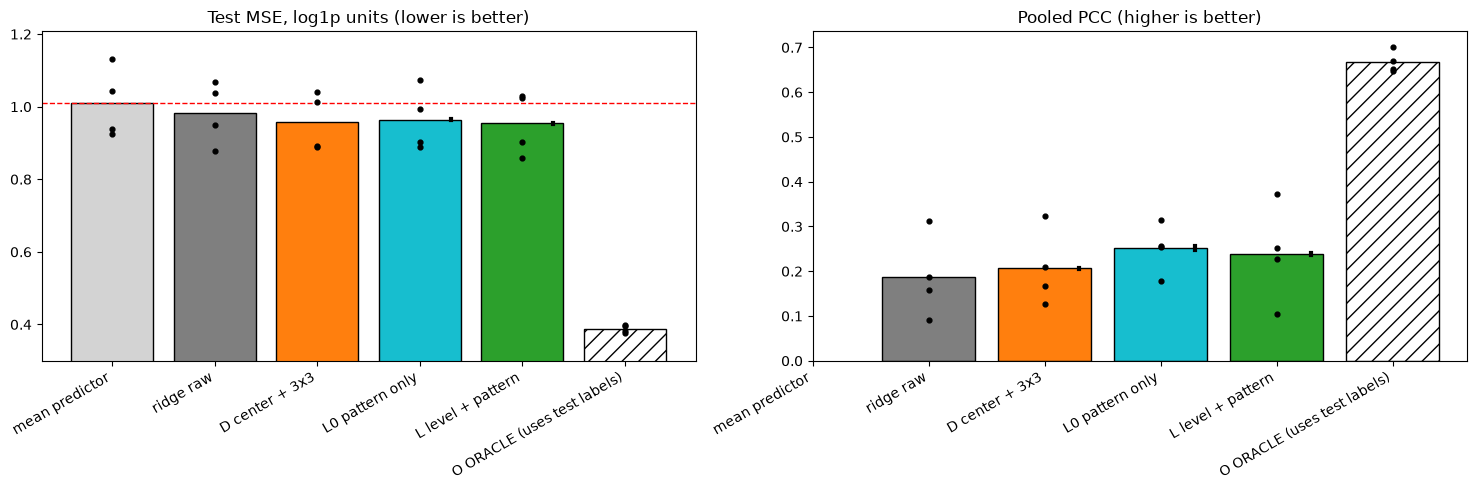

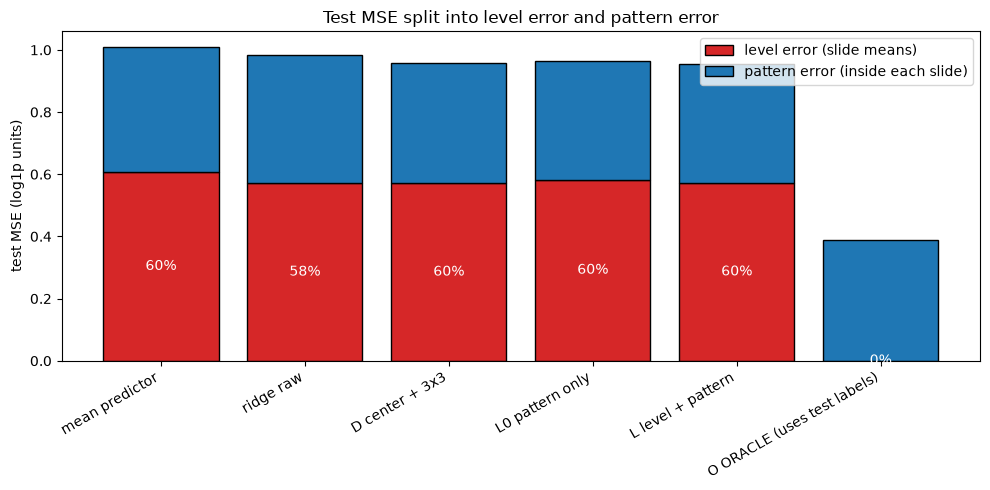

In [22]:
colors = {
    "mean predictor": "lightgrey",
    "ridge raw": "tab:gray",
    SETUP_NAMES["D"]: "tab:orange",
    SETUP_NAMES["L0"]: "tab:cyan",
    SETUP_NAMES["L"]: "tab:green",
    SETUP_NAMES["O"]: "white",
}
setup_names = list(SETUP_NAMES.values())

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
x = np.arange(len(model_order))
for ax, column, summary_column, label in [(axes[0], "MSE", "test_MSE", "MSE"), (axes[1], "PCC", "pooled_PCC", "PCC")]:
    for i, model_name in enumerate(model_order):
        values = fold_scores.loc[fold_scores["model"] == model_name, column]
        if values.notna().any():
            hatch = "//" if model_name == SETUP_NAMES["O"] else None
            ax.bar(i, values.mean(), color=colors[model_name], edgecolor="black", hatch=hatch)
            ax.scatter(np.full(len(values), i), values, color="black", s=12, zorder=3)
        if model_name in setup_names:
            row = summary[summary["model"] == model_name].iloc[0]
            half = row[f"seed_{label}_range"] / 2
            ax.plot([i + 0.3, i + 0.3], [row[summary_column] - half, row[summary_column] + half], color="black", linewidth=3)
    ax.set_xticks(x)
    ax.set_xticklabels(model_order, rotation=30, ha="right")
axes[0].set_title("Test MSE, log1p units (lower is better)")
axes[1].set_title("Pooled PCC (higher is better)")
mean_mse = summary.loc[summary["model"] == "mean predictor", "test_MSE"].iloc[0]
axes[0].axhline(mean_mse, color="red", linestyle="--", linewidth=1)
low = fold_scores["MSE"].min()
high = fold_scores["MSE"].max()
axes[0].set_ylim(low - 0.1 * (high - low), high + 0.1 * (high - low))
plt.tight_layout()
save_figure("1_mse_and_pcc.png")
plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
split_rows = summary.set_index("model").reindex(model_order)
ax.bar(x, split_rows["level_error"], color="tab:red", edgecolor="black", label="level error (slide means)")
ax.bar(x, split_rows["pattern_error"], bottom=split_rows["level_error"], color="tab:blue", edgecolor="black",
       label="pattern error (inside each slide)")
for i, model_name in enumerate(model_order):
    share = split_rows.loc[model_name, "level_share"]
    ax.text(i, split_rows.loc[model_name, "level_error"] / 2, f"{share:.0%}", ha="center", va="center", color="white")
ax.set_xticks(x)
ax.set_xticklabels(model_order, rotation=30, ha="right")
ax.set_ylabel("test MSE (log1p units)")
ax.set_title("Test MSE split into level error and pattern error")
ax.legend()
plt.tight_layout()
save_figure("2_error_split.png")
plt.show()

## Step 16. Best check (report only)

The usual rule: a setup would qualify to replace MLP_JK_Best if its **validation PCC is higher** than the current best's and its validation NRMSE is no worse than the mean predictor's. Test scores are not used, and the oracle O is never considered.

**This notebook does not change MLP_JK_Best.** It only writes `best_check.csv`; the decision is made after looking at the results.

In [23]:
best_rows = []
for setup in REAL_SETUPS:
    row = summary[summary["model"] == SETUP_NAMES[setup]].iloc[0]
    passes = row["val_NRMSE"] <= row["val_mean_predictor_NRMSE"]
    best_rows.append({
        "setup": setup,
        "val_PCC": row["val_PCC"],
        "val_NRMSE": row["val_NRMSE"],
        "val_mean_predictor_NRMSE": row["val_mean_predictor_NRMSE"],
        "passes_NRMSE_rule": passes,
        "current_best_val_PCC": best_val_PCC,
        "would_beat_best": passes and row["val_PCC"] > best_val_PCC,
    })
best_check = pd.DataFrame(best_rows)
print(best_check.round(4).to_string(index=False))
if best_check["would_beat_best"].any():
    print("\nAt least one setup passes the rule. MLP_JK_Best is NOT changed here; this is for review.")
else:
    print("\nNo setup passes the rule. MLP_JK_Best is unchanged.")

setup  val_PCC  val_NRMSE  val_mean_predictor_NRMSE  passes_NRMSE_rule  current_best_val_PCC  would_beat_best
    D   0.2076     1.0888                    1.1129               True                0.2256            False
   L0   0.1745     1.0933                    1.1129               True                0.2256            False
    L   0.2031     1.0858                    1.1129               True                0.2256            False

No setup passes the rule. MLP_JK_Best is unchanged.


## Step 17. Save results and add them to the log

`all_results.csv` gets one row each for the mean predictor, ridge raw, D, L0, L and the oracle O (clearly named as an oracle). If this notebook is run again, its old rows are replaced instead of duplicated.

In [24]:
summary.to_csv(os.path.join(OUT_DIR, "summary.csv"), index=False)
fold_scores.to_csv(os.path.join(OUT_DIR, "fold_scores.csv"), index=False)
comparisons.to_csv(os.path.join(OUT_DIR, "comparisons.csv"), index=False)
best_check.to_csv(os.path.join(OUT_DIR, "best_check.csv"), index=False)
level_table.to_csv(os.path.join(OUT_DIR, "level_model.csv"), index=False)
error_split.to_csv(os.path.join(OUT_DIR, "error_split.csv"), index=False)
pooled.to_csv(os.path.join(OUT_DIR, "pooled_gene_scores.csv"), index=False)
within.to_csv(os.path.join(OUT_DIR, "within_patient_gene_scores.csv"), index=False)
val_scores.to_csv(os.path.join(OUT_DIR, "validation_scores.csv"), index=False)
chosen_settings.to_csv(os.path.join(OUT_DIR, "chosen_settings.csv"), index=False)

settings = {
    "notebook": NOTEBOOK_NAME,
    "setup_names": SETUP_NAMES,
    "neighbor_distance": NEIGHBOR_DISTANCE,
    "n_pcs": N_PCS,
    "slide_pcs": SLIDE_PCS,
    "n_folds": N_FOLDS,
    "n_inner_folds": N_INNER_FOLDS,
    "n_genes": N_GENES,
    "alphas": [float(a) for a in ALPHAS],
    "min_test_sd": MIN_TEST_SD,
    "seed": SEED,
    "hidden_size": HIDDEN_SIZE,
    "dropout": DROPOUT,
    "weight_decay": WEIGHT_DECAY,
    "learning_rate": LEARNING_RATE,
    "batch_size": BATCH_SIZE,
    "max_epochs": MAX_EPOCHS,
    "patience": PATIENCE,
    "shrink_factors": SHRINK_FACTORS,
    "n_val_groups": N_VAL_GROUPS,
    "n_final_seeds": N_FINAL_SEEDS,
    "device": str(device),
    "torch_version": torch.__version__,
}
with open(os.path.join(OUT_DIR, "settings.json"), "w") as f:
    json.dump(settings, f, indent=2)

if LOG_RESULTS:
    today = datetime.date.today().isoformat()
    log_rows = []
    for _, row in summary.iterrows():
        log_rows.append({
            "notebook": NOTEBOOK_NAME,
            "condition": row["model"],
            "pooled_PCC": row["pooled_PCC"],
            "within_patient_PCC": row["within_PCC"],
            "NRMSE": row["NRMSE"],
            "mean_predictor_NRMSE": mean_predictor_nrmse,
            "val_PCC": row.get("val_PCC", np.nan),
            "val_NRMSE": row.get("val_NRMSE", np.nan),
            "date": today,
        })
    new_rows = pd.DataFrame(log_rows)
    if os.path.exists(RESULTS_LOG):
        old_rows = pd.read_csv(RESULTS_LOG)
        old_rows = old_rows[old_rows["notebook"] != NOTEBOOK_NAME]
        new_rows = pd.concat([old_rows, new_rows], ignore_index=True)
    new_rows.to_csv(RESULTS_LOG, index=False)
    print(new_rows.tail(8).round(4).to_string(index=False))

print("\nSaved to", OUT_DIR)
for name in sorted(os.listdir(OUT_DIR)):
    print("  ", name)

 notebook                   condition  pooled_PCC  within_patient_PCC  NRMSE  mean_predictor_NRMSE  val_PCC  val_NRMSE       date
MLP_JK_05            S center + slide      0.2306              0.1968 1.0798                1.0997   0.1992     1.0939 2026-11-14
MLP_JK_05     DS center + 3x3 + slide      0.2385              0.1920 1.0763                1.0997   0.2086     1.0947 2026-11-14
MLP_JK_06              mean predictor         NaN                 NaN 1.0997                1.0997      NaN        NaN 2026-11-14
MLP_JK_06                   ridge raw      0.1868              0.1514 1.0917                1.0997      NaN        NaN 2026-11-14
MLP_JK_06              D center + 3x3      0.2064              0.1584 1.0709                1.0997   0.2076     1.0888 2026-11-14
MLP_JK_06             L0 pattern only      0.2512              0.1978 1.0760                1.0997   0.1745     1.0933 2026-11-14
MLP_JK_06           L level + pattern      0.2390              0.1995 1.0689              

## Summary in plain words: can we fix each slide's level from its images?

**Checks first**
- Ridge on raw embeddings reproduced Notebook 5 (pooled PCC 0.1868).
- D reproduced MLP_JK_03's setup D exactly (test MSE 0.9584, pooled PCC 0.2064).
- In every fold and for every model, level error + pattern error add up to the test MSE.

### What each score means

| Score | What it means | Good vs. bad |
|---|---|---|
| **Test MSE** (the loss) | Average squared difference between predicted and true expression (log1p), over all test spots and the 50 genes | Lower is better. Mean predictor = 1.009 |
| **Level error** | The part of the test MSE that comes from each slide's **predicted mean** being off from its **true mean** | Lower is better. 0 = every slide's overall level is exactly right |
| **Pattern error** | The part that's left **inside** each slide once the slide means are matched: getting the ups and downs within the tissue right | Lower is better |
| **NRMSE** | The error divided by the gene's spread | Lower is better; below the mean predictor (1.100) = better than guessing the average |
| **Pooled PCC** | Correlation between predicted and true expression over all test spots, across slides | 0 = no relation, 1 = perfect |
| **Within-patient PCC** | The same correlation inside one patient at a time (~3 slides each) | Higher is better |
| **Validation PCC / NRMSE** | The same scores on held-out *training* patients. The only scores used for choosing | Higher PCC, lower NRMSE |
| **Seed spread** | How much a score moves between the 3 model seeds | A difference smaller than this could be luck |

A difference is called **real** here only if it is bigger than the seed spread **and** holds in at least 3 of 4 folds.

### What we got

| Setup | Test MSE | Level error | Pattern error | Level share | Pooled PCC | Within-patient PCC | NRMSE | Validation PCC | k |
|---|---|---|---|---|---|---|---|---|---|
| mean predictor | 1.009 | 0.608 | 0.402 | 60% | — | — | 1.100 | — | — |
| ridge raw | 0.984 | 0.571 | 0.413 | 58% | 0.187 | 0.151 | 1.092 | — | — |
| **D** center + 3×3 | 0.958 | **0.571** | 0.388 | 60% | 0.206 | 0.158 | 1.071 | **0.208** | 0.4 ×4 |
| **L0** pattern only | 0.965 | 0.583 | **0.382** | 60% | **0.251** | 0.198 | 1.076 | 0.175 | 0.6/0.4/0.6/0.4 |
| **L** level + pattern | **0.954** | 0.572 | **0.382** | 60% | 0.239 | **0.200** | **1.069** | 0.203 | 0.6/0.4/0.6/0.4 |
| **O ORACLE** (uses test labels) | 0.388 | 0 | 0.388 | 0% | 0.667 | 0.256 | 0.717 | — | — |

Seed spread: test MSE ≤ 0.003, pooled PCC ≤ 0.009.

**The level model on its own** (MSE of predicted vs. true **test slide means**, each slide counted equally):

| Fold | Ridge | Training gene mean | Ridge − mean | Slides where ridge is closer |
|---|---|---|---|---|
| 0 | 0.650 | 0.627 | +0.023 (worse) | 5 of 17 |
| 1 | 0.691 | 0.733 | −0.042 | 13 of 18 |
| 2 | 0.522 | 0.515 | +0.007 (worse) | 9 of 18 |
| 3 | 0.500 | 0.540 | −0.040 | 15 of 15 |
| overall | **0.591** | **0.604** | **−0.013** | 42 of 68 |

Validation chose the same, strongly shrunk alpha in every fold (≈ 4.9 × 10⁴).

### The answers

**How big is the level problem?** It's bigger than we thought: about **60%** of the test MSE is level error, for every model, including the mean predictor. (Here a "level" is one slide's mean. Patient-level offsets are part of this, as are differences between a patient's slides.) The oracle shows the ceiling: with every test slide's mean exactly right, test MSE would drop from 0.958 to **0.388** and pooled PCC would rise from 0.21 to 0.67. Getting levels right is by far the biggest thing left to gain.

**Can the slide's images predict its level? Only very weakly.**
- **Ridge vs. the training mean:** ridge from the slide-average embedding beats just using the training gene mean by only 2% (0.591 vs. 0.604). It's better in 2 folds and worse in the other 2, though it's closer on 42 of 68 slides.
- **The separate level model adds nothing over D:** D's MLP already gets the same level error on its own (D 0.571, L 0.572).
- **Conclusion:** most of each slide's overall level isn't visible in the image embeddings. It may come from things the images don't show, such as sequencing depth or batch differences between slides; that's a guess, not something tested here.

**L0 vs. D (does centering alone help?)**
- **Pattern error:** slightly but really better, −0.006 in all 4 folds, about twice the seed spread. Training on slide-centered targets makes the within-slide pattern a bit more accurate.
- **Test MSE:** not better (+0.006, better in only 1 of 4 folds), because L0 gives up D's level information and its level error goes up (+0.012).
- **Pooled PCC:** much higher (0.251 vs. 0.206, higher in 3 of 4 folds) — the highest test pooled PCC of any model so far. The likely reason: D's slide-to-slide shifts are mostly wrong, and leaving them out removes noise from the ranking.

**L vs. D and L vs. L0 (does the level model help?)**
- **L vs. D:** test MSE −0.005 (better in only 2 of 4 folds, so **not real**). The real pattern gain (−0.006, 4 of 4 folds) is cancelled in folds 0 and 2 by worse levels. Pooled PCC +0.033 (3 of 4 folds, real on test).
- **L vs. L0:** adding the level model lowers the error in folds 1 and 3 and raises it in folds 0 and 2 (mean −0.011, 2 of 4 folds). It mirrors the level model's own fold-by-fold record above.

**Validation doesn't confirm the test PCC gains.** On validation patients, D (0.208) is above L (0.203) and well above L0 (0.175). As in MLP_JK_05, the large test PCC gains of L0 and L aren't seen on validation, so treat them with caution.

**Within-patient PCC** rises from 0.158 (D) to about 0.20 (L0, L). For L0, which adds no slide-level information at all, this is a real improvement in ranking spots within each tissue, not a section-level effect. L's value may be partly section-level.

### Bottom line
Each slide's overall level is the single largest source of error (~60% of test MSE; a perfect level would cut the error by 60%), but the slide's image embeddings barely predict it (2% better than the training mean, and only in 2 of 4 folds). Separating level and pattern makes the **within-slide pattern** slightly but consistently more accurate (all 4 folds) and raises the test ranking scores, but it doesn't lower the total test error in a reliable way.

### Best model
No setup passes the rule against MLP_JK_Best (setup E, validation PCC 0.226): the best here is D at 0.208, then L at 0.203. `best_check.csv` reports this. **MLP_JK_Best was not changed**, as requested.